# O que os custos registrados revelam sobre as dispensações?

## Sprint 2 - PyAnalytics



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:

df = pd.read_csv("dispensacao_analitico.csv")

df.head()

,competencia_inicial,competencia_final,ups_nome,ups_codigo,bairro_nome,bairro_codigo,centro_custo_nome,centro_custo_codigo,material_nome,material_nome_base,...,data,saida,usuario,fabricante_codigo,fabricante_nome,lote,numero_receita,validade,quantidade,custo_medio
0,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CARBONATO DE LITIO - 300MG - COMPRIMIDO,CARBONATO DE LITIO,...,2025-09-02,776110,X,41.0,CRISTALIA,23100497,NaN,2025-10-02,90,0.19
1,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CLORPROMAZINA - 25MG - COMPRIMIDO,CLORPROMAZINA,...,2025-09-18,781751,X,41.0,CRISTALIA,50023423,NaN,2027-01-30,240,0.28
2,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,IMIPRAMINA - 25MG - COMPRIMIDO,IMIPRAMINA,...,2025-09-09,778225,X,41.0,CRISTALIA,50025335,NaN,2027-01-31,180,0.44
3,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,MIRTAZAPINA - 45MG - COMPRIMIDO,MIRTAZAPINA,...,2025-09-18,781751,X,2.0,PRATI DONADUZZI,25D360,NaN,2027-03-13,60,0.86
4,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,VENLAFAXINA - 75MG - COMPRIMIDO,VENLAFAXINA,...,2025-09-02,776110,X,40.0,AUROBINDO,VWB25001,NaN,2027-12-31,120,0.36


# 1. Preparação dos Dados & EDA (Exploratory Data Analysis)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 220815 entries, 0 to 220814
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   competencia_inicial              220815 non-null  int64  
 1   competencia_final                219080 non-null  float64
 2   ups_nome                         220815 non-null  str    
 3   ups_codigo                       220815 non-null  int64  
 4   bairro_nome                      220815 non-null  str    
 5   bairro_codigo                    220792 non-null  float64
 6   centro_custo_nome                220815 non-null  str    
 7   centro_custo_codigo              21543 non-null   float64
 8   material_nome                    220815 non-null  str    
 9   material_nome_base               220815 non-null  str    
 10  material_descricao_complementar  220815 non-null  str    
 11  material_tipo                    220815 non-null  str    
 12  classe_terape

A base é robusta e estatisticamente confiável para responder às perguntas centrais, as variáveis essenciais: quantidade, custo_medio, material_nome_base e a coluna temporal data, estão 100% preenchidas sem nenhum valor ausente (220.815 registros válidos).

In [5]:
# 1. Defini uma lista com as colunas de interesse
colunas_interesse = [
    'quantidade',
    'custo_medio',
    'data',
    'material_nome_base',
    'material_nome',
    'centro_custo_nome',
    'fabricante_nome',
    'classe_terapeutica',
    'numero_receita',
]

# 2. Contei os nulos diretamente em cada coluna
df[colunas_interesse].isnull().sum()

quantidade                 0
custo_medio                0
data                       0
material_nome_base         0
material_nome              0
centro_custo_nome          0
fabricante_nome           66
classe_terapeutica      8473
numero_receita        213616
dtype: int64

**fabricante_nome:** Os 66 registros sem fabricante são todos do item SERINGA 1ML (que também não tem lote nem validade cadastrados). Por representar apenas 0,03% do total, trata-se de uma inconsistência cadastral pontual que não impacta a análise global.

**classe_terapeutica:** Esses nulos não são erros aleatórios, mas sim materiais e insumos hospitalares/aplicadores que não são medicamentos (como Agulha Descartável, Seringa Estéril, Caneta de Insulina e Reidratante Oral).

**numero_receita:** Quase 97% dos atendimentos não possuem o número da receita registrado no sistema de farmácia. Portanto, essa coluna não tem utilidade analítica e não pode ser usada para contar pacientes ou prescrições.

In [6]:
# 1. Tratamento de nulos das colunas identificadas
df['fabricante_nome'] = df['fabricante_nome'].fillna('NÃO INFORMADO')
df['classe_terapeutica'] = df['classe_terapeutica'].fillna('INSUMO / OUTROS')
df = df.drop(columns=['numero_receita'], errors='ignore')

# Criação da coluna custo_total 
if 'custo_total' not in df.columns:
    df['custo_total'] = df['quantidade'] * df['custo_medio']

# 3. Validação e confirmação se ainda resta algum nulo nas colunas tratadas
df[[
        'quantidade',
        'custo_medio',
        'custo_total',
        'fabricante_nome',
        'classe_terapeutica',]].isnull().sum()

quantidade            0
custo_medio           0
custo_total           0
fabricante_nome       0
classe_terapeutica    0
dtype: int64

In [7]:


# 2. Geração do describe focado nas variáveis analíticas
df[['quantidade', 'custo_medio', 'custo_total']].describe()

,quantidade,custo_medio,custo_total
count,220815.000000,220815.000000,220815.000000
mean,46.084437,1.007531,10.061950
std,43.502139,3.008901,19.975742
min,1.000000,0.000000,0.000000
25%,20.000000,0.050000,2.400000
50%,30.000000,0.160000,4.800000
75%,60.000000,0.320000,9.500000
max,950.000000,35.820000,941.700000


A análise descritiva revela que a dispensação pública é predominantemente composta por medicamentos de baixo custo unitário (75% custam até 0,32 reais) e volumes padronizados para tratamentos mensais (mediana de 30 unidades e 4,80 reais por retirada). No entanto, há forte assimetria provocada por registros atípicos (outliers), onde o custo total por saída alcança até 941,70 reais e o volume unitário atinge 950 unidades, o que explica por que a média de custo (10,06 reais) é significativamente superior à mediana.



In [37]:
# 1. Conversão da coluna de data para o formato datetime
df['data'] = pd.to_datetime(df['data'])

# 2. Criação da coluna 'custo_total'
df['custo_total'] = df['quantidade'] * df['custo_medio']

# 3. Criar uma coluna de Ano-Mês para facilitar agrupamentos temporais
df['ano_mes'] = df['data'].dt.to_period('M').astype(str)

# 4. Conferir os novos campos criados
df[['data', 'ano_mes', 'material_nome_base', 'quantidade', 'custo_medio', 'custo_total']].head()

,data,ano_mes,material_nome_base,quantidade,custo_medio,custo_total
0,2025-09-02,2025-09,CARBONATO DE LITIO,90,0.19,17.1
1,2025-09-18,2025-09,CLORPROMAZINA,240,0.28,67.2
2,2025-09-09,2025-09,IMIPRAMINA,180,0.44,79.2
3,2025-09-18,2025-09,MIRTAZAPINA,60,0.86,51.6
4,2025-09-02,2025-09,VENLAFAXINA,120,0.36,43.2


# A importância e relevância dos medicamentos (Quantidade X Custo) na vida do Cidadão

1.  Como os custos variam ao longo do período?

In [43]:
# Agrupamento mensal somando custo e quantidade
#Funções de agregação
evolucao_mensal = (
    #df[df['ano_mes'] != '2026-08'],
    #Deixei comentado o código acima, pois removi de um outro jeito, e achei essencial deixar o código original comentado para referência futura.
    df.groupby('ano_mes')
    .agg(
        custo_total=('custo_total', 'sum'),
        quantidade_total=('quantidade', 'sum'),
        total_atendimentos=('saida', 'nunique'),
    )
    .reset_index()
)

print(evolucao_mensal)

    ano_mes  custo_total  quantidade_total  total_atendimentos
0   2025-08    223630.87            957041                7877
1   2025-09    210444.29            911453                8317
2   2025-10    195531.61            890965                8366
3   2025-11    164921.43            759042                7146
4   2025-12    179716.91            828313                7271
5   2026-01    165517.63            779264                6834
6   2026-02    163462.29            770992                6814
7   2026-03    182949.97            861769                8071
8   2026-04    185613.82            882261                7951
9   2026-05    172274.99            794354                7099
10  2026-06    168116.07            814041                7151
11  2026-07    191399.47            843379                7964


Os gastos e o volume de dispensação são estáveis ao longo do ano (média de 163 mil reais a 195 mil reais e ~8 mil atendimentos/mês), apresentando leve queda no período de férias (novembro a fevereiro) e uma redução artificial em agosto/2026 decorrente de dados parciais.

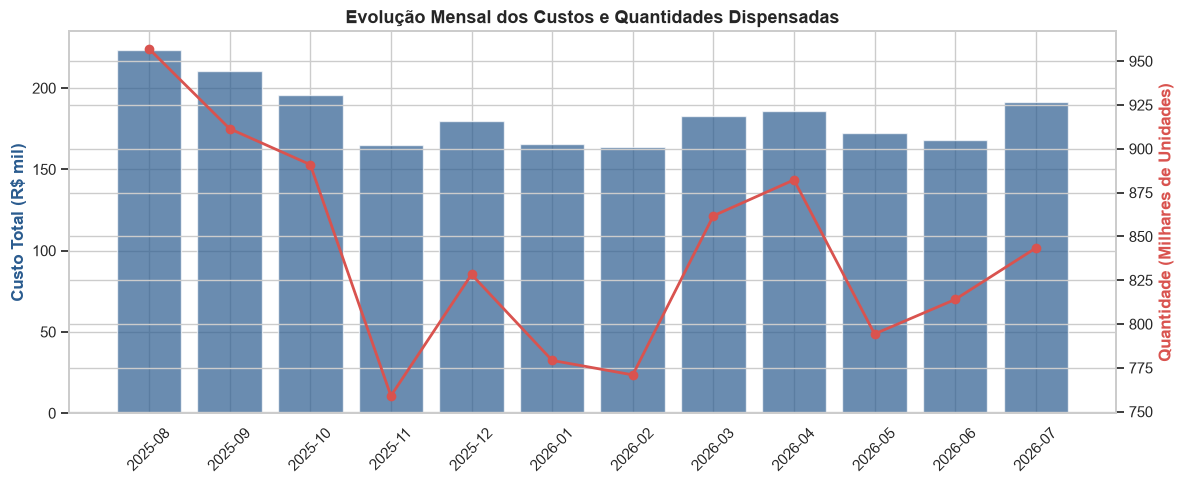

In [ ]:
# 1. Filtra removendo explicitamente o mês 2026-08
#df_plot = evolucao_mensal[evolucao_mensal['ano_mes'] != '2026-08']
#Deixei comentado o código acima, pois removi de um outro jeito, e achei essencial deixar o código original comentado para referência futura.

# 2. Gera o gráfico usando df_plot
fig, ax1 = plt.subplots(figsize=(12, 5))

# Eixo 1: Custo Total (Barras)
ax1.bar(
    df_plot['ano_mes'],
    df_plot['custo_total'] / 1e3,
    color='#2b5c8f',
    alpha=0.7,
    label='Custo Total (Mil R$)'
)
ax1.set_ylabel('Custo Total (R$ mil)', color='#2b5c8f', weight='bold')
ax1.tick_params(axis='x', rotation=45)

# Eixo 2: Quantidade (Linha)
ax2 = ax1.twinx()
ax2.plot(
    df_plot['ano_mes'],
    df_plot['quantidade_total'] / 1e3,
    color='#d9534f',
    marker='o',
    linewidth=2,
    label='Qtd Dispensada (Mil)'
)
ax2.set_ylabel('Quantidade (Milhares de Unidades)', color='#d9534f', weight='bold')

plt.title('Evolução Mensal dos Custos e Quantidades Dispensadas', fontsize=13, weight='bold')
fig.tight_layout()
plt.show()

O gráfico da variação temporal evidencia uma forte aderência entre o custo financeiro (barras) e o volume físico entregue (linha vermelha) ao longo de todo o período, confirmando que as variações nos gastos municipais acompanham diretamente o ritmo da demanda por unidades dispensadas em cada mês.

2. Quais medicamentos mais influenciam os valores observados?

In [11]:
# Agrupar por medicamento base e somar o custo
top_medicamentos_custo = (
    df.groupby('material_nome_base')
    .agg(
        custo_total=('custo_total', 'sum'),
        quantidade_total=('quantidade', 'sum'),
        qtd_dispensacoes=('quantidade', 'count'),
    )
    .sort_values(by='custo_total', ascending=False)
    .reset_index()
)

# Adicionar coluna de percentual sobre o custo total geral
top_medicamentos_custo['pct_do_total'] = (
    top_medicamentos_custo['custo_total'] / df['custo_total'].sum()
) * 100

# Exibir os 10 medicamentos mais caros
top_medicamentos_custo.head(10)

,material_nome_base,custo_total,quantidade_total,qtd_dispensacoes,pct_do_total
0,INSULINA HUMANA NPH,244831.43,27102,6914,11.019362
1,LEVODOPA + BENSERAZIDA,147047.90,104818,859,6.618325
2,AMOXICILINA+CLAVULANATO,124401.51,103167,5264,5.599057
3,METOPROLOL,108592.60,295040,5694,4.887531
4,CLOMIPRAMINA,93283.80,88410,613,4.198513
5,LEVOTIROXINA,92817.82,582964,11464,4.177540
6,ACIDO VALPROICO,81553.50,290350,1463,3.670556
7,GLICLAZIDA,74969.70,312240,6125,3.374233
8,CARBAMAZEPINA,57830.82,351726,2296,2.602847
9,INSULINA HUMANA REGULAR,53675.05,5076,2543,2.415804


Apenas estes 10 medicamentos concentram 48,56% de todo o custo financeiro do município, com a Insulina Humana NPH liderando isolada ao absorver 11,02% dos gastos (R$ 244,8 mil) com apenas 27,1 mil unidades, enquanto itens de altíssimo volume como a Levotiroxina (582,9 mil unidades) respondem por apenas 4,18% do custo, evidenciando que o impacto orçamentário é puxado pelo alto valor unitário de tratamentos especializados e biológicos, e não pela quantidade distribuída.

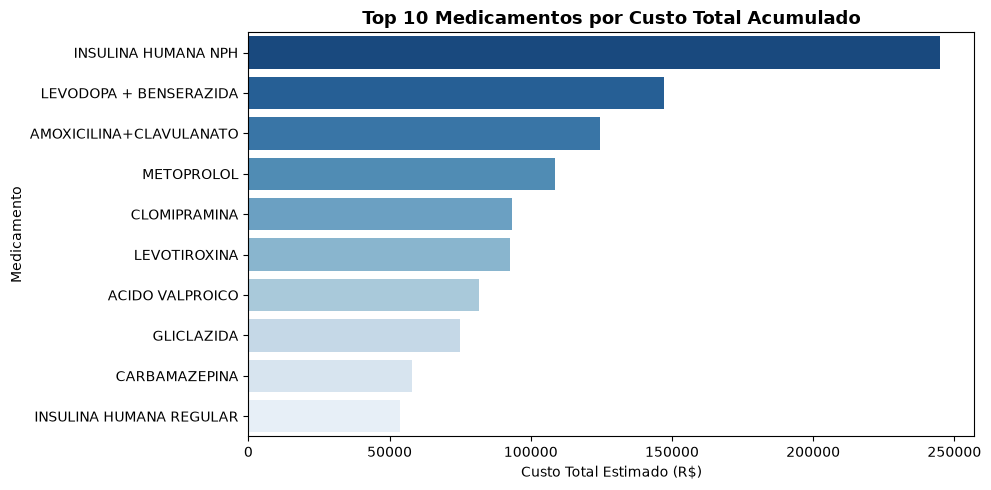

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_medicamentos_custo.head(10),
    x='custo_total',
    y='material_nome_base',
    palette='Blues_r',
    hue='material_nome_base',
    legend=False,
)
plt.title('Top 10 Medicamentos por Custo Total Acumulado', fontsize=13, weight='bold')
plt.xlabel('Custo Total Estimado (R$)')
plt.ylabel('Medicamento')
plt.tight_layout()
plt.show()

O gráfico demonstra uma acentuada concentração de gastos liderada pela Insulina Humana NPH (244,8 mil reais), que combinada à Levodopa + Benserazida (147,0 mil reais) e à Amoxicilina + Clavulanato (124,4 mil reais) forma um trio que sozinho consome mais de meio milhão de reais (23,24% de todo o orçamento municipal), evidenciando que o controle orçamentário da saúde pública depende criticamente da gestão eficiente de estoque e compras desses tratamentos de alto custo para diabetes, doenças neurodegenerativas e infecções bacterianas.

3. Medicamentos mais dispensados também representam os maiores custos?

In [13]:
# Comparar o Top 5 em Quantidade vs Top 5 em Custo
top_qtd = top_medicamentos_custo.sort_values(by='quantidade_total', ascending=False).head(5)
top_custo = top_medicamentos_custo.sort_values(by='custo_total', ascending=False).head(5)

print("Top 5 em Quantidade:\n", top_qtd[['material_nome_base', 'quantidade_total', 'custo_total']])
print("\nTop 5 em Custo:\n", top_custo[['material_nome_base', 'custo_total', 'quantidade_total']])

# Calcular correlação linear de Pearson e de postos de Spearman
corr_pearson = top_medicamentos_custo['quantidade_total'].corr(top_medicamentos_custo['custo_total'])
corr_spearman = top_medicamentos_custo['quantidade_total'].corr(top_medicamentos_custo['custo_total'], method='spearman')

print(f"\nCorrelação de Pearson (Volume x Custo): {corr_pearson:.2f}")
print(f"Correlação de Spearman: {corr_spearman:.2f}")

Top 5 em Quantidade:
    material_nome_base  quantidade_total  custo_total
15         FLUOXETINA            631107     35310.75
28      AMITRIPTILINA            616484     22079.32
5        LEVOTIROXINA            582964     92817.82
18          OMEPRAZOL            488984     32914.16
26       SINVASTATINA            456377     22818.85

Top 5 em Custo:
         material_nome_base  custo_total  quantidade_total
0      INSULINA HUMANA NPH    244831.43             27102
1   LEVODOPA + BENSERAZIDA    147047.90            104818
2  AMOXICILINA+CLAVULANATO    124401.51            103167
3               METOPROLOL    108592.60            295040
4             CLOMIPRAMINA     93283.80             88410

Correlação de Pearson (Volume x Custo): 0.32
Correlação de Spearman: 0.76


Não, medicamentos mais dispensados não geram os maiores custos: a fraca correlação linear ($r = 0,32$) mostra que itens massivos como a Fluoxetina (631 mil unidades) custam pouco (35,3 mil reais) devido ao valor unitário de centavos, enquanto tratamentos especializados como a Insulina NPH consomem a maior fatia do orçamento (244,8 mil reais) com apenas 27,1 mil unidades (9,03 reais/unid), provando que o impacto financeiro da rede é ditado pelo alto custo unitário de itens específicos, e não pelo volume distribuído.

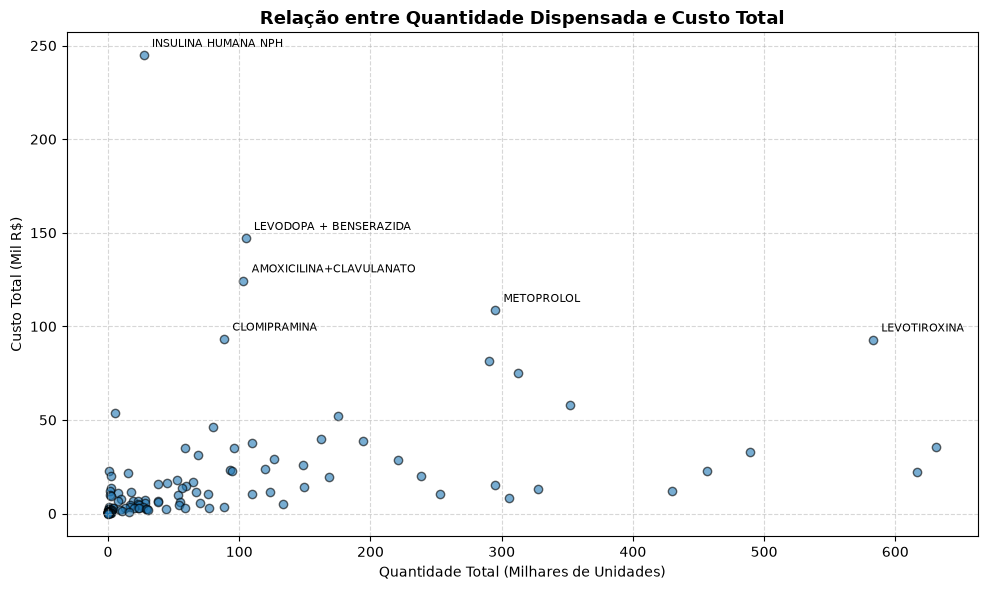

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(
    top_medicamentos_custo['quantidade_total'] / 1e3,
    top_medicamentos_custo['custo_total'] / 1e3,
    alpha=0.6,
    color='#1f77b4',
    edgecolors='k',
)

# Destacar os principais medicamentos anotando os nomes
for _, row in top_medicamentos_custo.head(6).iterrows():
  plt.annotate(
      row['material_nome_base'],
      (row['quantidade_total'] / 1e3, row['custo_total'] / 1e3),
      fontsize=8,
      xytext=(6, 6),
      textcoords='offset points',
  )

plt.title('Relação entre Quantidade Dispensada e Custo Total', fontsize=13, weight='bold')
plt.xlabel('Quantidade Total (Milhares de Unidades)')
plt.ylabel('Custo Total (Mil R$)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

O gráfico de dispersão confirma visualmente a ausência de relação direta entre volume e custo: a grande maioria dos medicamentos (mais de 90%) forma um agrupamento denso de baixo custo na base inferior (abaixo de 50 mil reais), enquanto a Insulina Humana NPH se destaca como um ponto fora da curva isolado no topo esquerdo (quase 250 mil reais com menos de 30 mil unidades), provando que o orçamento municipal não é pressionado pelos itens de distribuição em massa (como a Levotiroxina, com mais de 580 mil unidades), mas sim pelo alto custo unitário de tratamentos biológicos especializados.

4. Quais diferenças ou valores fora do padrão merecem investigação?

In [15]:
# 1. Identificar registros com custos unitários atípicos (mais caros)
outliers_custo_unitario = df.sort_values(by='custo_medio', ascending=False)[
    ['data', 'material_nome', 'custo_medio', 'quantidade', 'custo_total', 'fabricante_nome']
].head(10)

# 2. Identificar registros com maiores quantidades em uma única saída
outliers_quantidade = df.sort_values(by='quantidade', ascending=False)[
    ['data', 'material_nome', 'quantidade', 'custo_medio', 'custo_total', 'centro_custo_nome']
].head(10)

# 3. Identificar os maiores custos totais por evento de dispensação
outliers_custo_evento = df.sort_values(by='custo_total', ascending=False)[
    ['data', 'material_nome', 'quantidade', 'custo_medio', 'custo_total', 'fabricante_nome']
].head(10)

print(outliers_custo_evento)

             data                                      material_nome  \
216740 2026-06-18    NIRMATRELVIR+RITONAVIR - 150+100MG - COMPRIMIDO   
89845  2025-12-02  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   
126677 2026-02-05  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   
220085 2026-08-03  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   
198701 2026-07-03  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   
15743  2025-08-04  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   
75615  2025-11-07  HEPARINA SÓDICA - HEPARINA SÓDICA - 5000/0,25 ...   
110266 2025-12-12  HEPARINA SÓDICA - HEPARINA SÓDICA - 5000/0,25 ...   
169265 2026-04-10                   CLOMIPRAMINA - 25MG - COMPRIMIDO   
23202  2025-09-01  LEVODOPA + BENSERAZIDA - LEVODOPA + BENSERAZID...   

        quantidade  custo_medio  custo_total fabricante_nome  
216740          30        31.39        941.7          PFIZER  
89845          360         1.87        673.2           ROCHE  
126677         360

Os dados revelam que os maiores custos por evento individual de dispensação concentram-se no tratamento de tecnologia avançada da COVID-19 (Nirmatrelvir + Ritonavir / Paxlovid), que lidera o ranking com 941,70 reais para apenas 30 comprimidos devido ao seu elevado custo unitário (31,39 reais/unid), e em dispensações trimestrais recorrentes do componente especializado para Parkinson (Levodopa + Benserazida), que domina a maior parte do Top 10 com retiradas acumuladas de 360 comprimidos avaliadas em R$ 673,20 por atendimento, demonstrando como terapias de alto valor agregado e protocolos de uso contínuo concentram picos financeiros em retiradas pontuais.

C:\Users\Manuel Etiene\AppData\Local\Temp\ipykernel_24828\4218655121.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top5, x='material_nome_base', y='quantidade', palette='Set2')


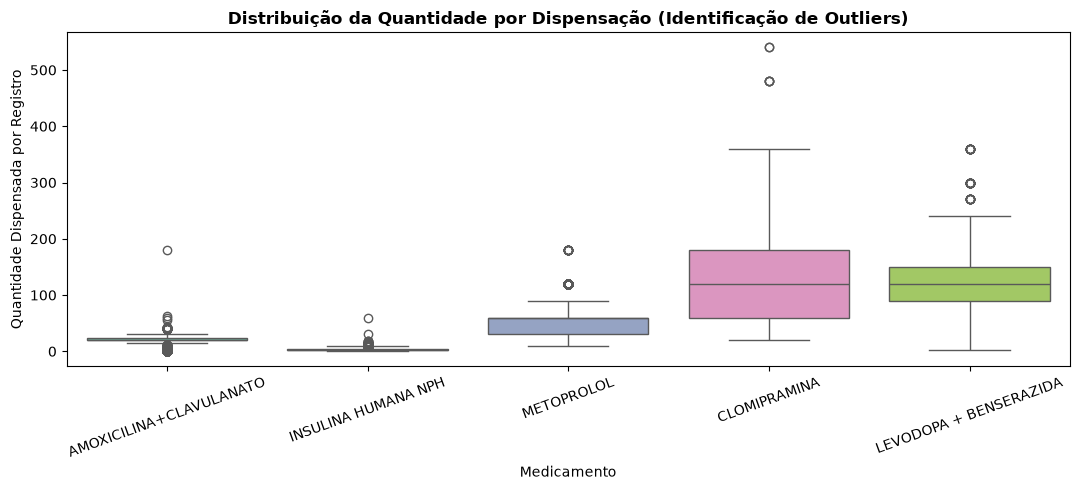

In [16]:
# Selecionar os 5 medicamentos com maior volume para ver a distribuição de quantidades por saída
top5_nomes = top_medicamentos_custo.head(5)['material_nome_base'].tolist()
df_top5 = df[df['material_nome_base'].isin(top5_nomes)]

plt.figure(figsize=(11, 5))
sns.boxplot(data=df_top5, x='material_nome_base', y='quantidade', palette='Set2')
plt.title('Distribuição da Quantidade por Dispensação (Identificação de Outliers)', fontsize=12, weight='bold')
plt.xlabel('Medicamento')
plt.ylabel('Quantidade Dispensada por Registro')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

O boxplot demonstra que a variabilidade da quantidade por atendimento reflete diretamente a duração e o tipo do protocolo clínico: enquanto medicamentos agudos ou biológicos fracionados (Amoxicilina + Clavulanato e Insulina Humana NPH) apresentam distribuições extremamente concentradas com baixas medianas (21 e 3 unidades por retirada), terapias crônicas neurológicas e psiquiátricas (Levodopa + Benserazida e Clomipramina) exibem grande dispersão (medianas de 120 comprimidos) com outliers expressivos que chegam a 360 e 540 unidades em um único atendimento, caracterizando retiradas trimestrais acumuladas de alto impacto físico e financeiro no balcão da farmácia.

# Amostra de diferentes períodos, medicamentos e fabricantes

In [17]:
# Análise por Fabricante
top_fabricantes = (
    df.groupby('fabricante_nome')
    .agg(
        custo_total=('custo_total', 'sum'),
        quantidade_total=('quantidade', 'sum'),
        itens_distintos=('material_nome_base', 'nunique'),
    )
    .sort_values(by='custo_total', ascending=False)
    .head(5)
    .reset_index()
)

print(top_fabricantes)

       fabricante_nome  custo_total  quantidade_total  itens_distintos
0                  EMS    254965.10           1032803               21
1  MINISTÉRIO DA SAÚDE    233916.12             30166                5
2      PRATI DONADUZZI    208505.59           1354110               25
3                ROCHE    147047.90            104818                1
4                CIMED    134193.43            908906                9


Fornecedores como EMS e Prati Donaduzzi lideram em volume de genéricos de massa, enquanto o Ministério da Saúde e a Roche têm alto impacto financeiro com poucos itens específicos (insulinas e Levodopa/Benserazida).

C:\Users\Manuel Etiene\AppData\Local\Temp\ipykernel_24828\140166797.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


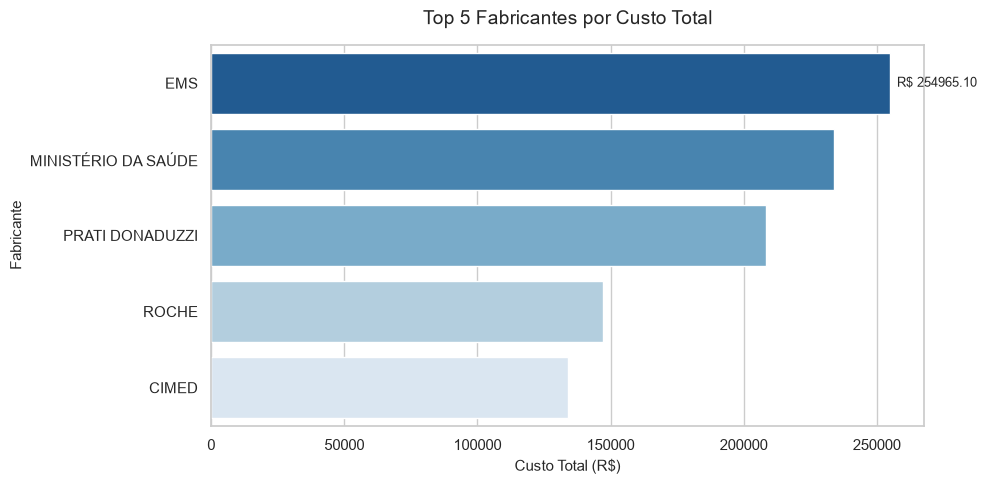

In [28]:
# Configuração do estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Criação do gráfico de barras horizontal (facilita ler os nomes dos fabricantes)
ax = sns.barplot(
    data=top_fabricantes,
    x='custo_total',
    y='fabricante_nome',
    palette='Blues_r'
)

# Adiciona os rótulos de valores nas barras
ax.bar_label(
    ax.containers[0], 
    fmt='R$ %.2f', 
    padding=5, 
    fontsize=9
)

# Títulos e labels
plt.title('Top 5 Fabricantes por Custo Total', fontsize=14, pad=15)
plt.xlabel('Custo Total (R$)', fontsize=11)
plt.ylabel('Fabricante', fontsize=11)

plt.tight_layout()
plt.show()

Os custos com fabricantes dividem-se entre alto volume em genéricos variados (EMS e Prati Donaduzzi) e alto valor unitário concentrado em poucos medicamentos especializados (Ministério da Saúde e Roche).

# Explicação sobre quais fatores parecem influenciar os resultados:


In [18]:
# Custo por Classe Terapêutica
custo_classe = (
    df.groupby('classe_terapeutica')['custo_total']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
print(custo_classe)

classe_terapeutica
ANTIDIABETICOS                                        373476.18
ANTIDEPRESSIVOS                                       314249.02
ANTICONVULSIVANTES                                    204737.67
ANTIPARKINSONIANOS                                    165308.10
ANTIBIOTICOS SISTEMICOS-ASSOCIACOES MEDICAMENTOSAS    124401.51
Name: custo_total, dtype: float64


A maior parte do orçamento público de dispensação é absorvida por terapias contínuas e de uso prolongado.

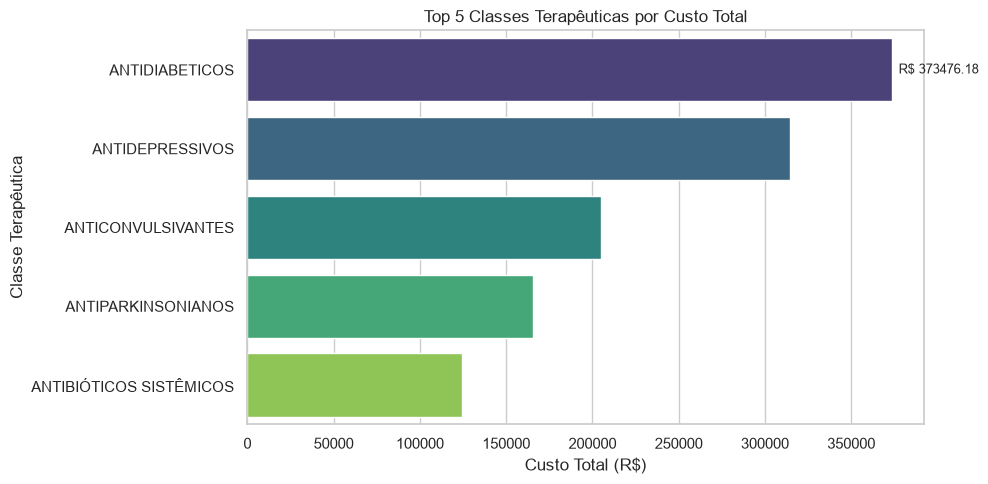

In [ ]:


plt.figure(figsize=(10, 5))

# Encurta o nome do último item para não poluir o eixo
classes_nomes = custo_classe.index.map(
    lambda x: "ANTIBIÓTICOS SISTÊMICOS" if "ANTIBIOTICOS" in x else x
)


ax = sns.barplot(
    x=custo_classe.values,
    y=classes_nomes,
    hue=classes_nomes,
    palette='viridis',
    legend=False
)

# Adiciona os rótulos de valores em Reais nas barras
ax.bar_label(
    ax.containers[0], 
    fmt='R$ %.2f', 
    padding=5, 
    fontsize=9
)


plt.title('Top 5 Classes Terapêuticas por Custo Total')
plt.xlabel('Custo Total (R$)')
plt.ylabel('Classe Terapêutica')

plt.tight_layout()
plt.show()

Os custos municipais são fortemente puxados por Antidiabéticos (373 mil reais), Antidepressivos (314 mil reais) e Anticonvulsivantes (204 mil reais).

# Conclusão

A análise dos dados revela que as classes de **Antidiabéticos**, **Antidepressivos** e **Anticonvulsivantes** constituem a espinha dorsal da assistência farmacêutica municipal, concentrando **R$ 892.462,87 (40,17% do custo total)** e mais de **3,21 milhões de unidades distribuídas (31,62% do volume total)**, com forte impacto financeiro de itens biológicos como as insulinas e alta demanda por suporte de saúde mental e neurológico. Como conselho de saúde, esses resultados reforçam a importância indispensável do **uso contínuo e sem interrupções abruptas** dessas medicações para evitar crises agudas e efeito rebote, além de destacar que o tratamento medicamentoso de condições crônicas como o diabetes e transtornos de humor alcança sua máxima eficácia quando aliado à **prática regular de atividade física, alimentação balanceada e manejo do estresse**.